# Etapa 3. Regresión logística múltiple (v3)
**Reto clima: vegetación y contaminación (SIMA, Monterrey)**

Modelo de dependencia: probabilidad de que la concentración **mensual** de un contaminante (PM10, PM2.5, NO2) sea *alta* en función de la vegetación (NDVI, cobertura verde), la meteorología y, **nuevo en v3, la ubicación de cada estación**.

Estructura: 0. Configuración · 1. Datos y ubicación · 2. Variable respuesta · 3. Preparación · 4. Multicolinealidad · 5. Modelo y resultados · 6. Validación de supuestos (incl. autocorrelación temporal y espacial) · 7. Eficiencia y errores (**validación temporal**) · 8. Variables más importantes

---
**Cambios de esta versión (v3)**
1. **Ubicación de las estaciones** (documento *Ubicación de las estaciones de monitoreo*): latitud, longitud y elevación entran a la base. En el modelo principal se usan `lat` y `elev` (ver sección 4 por qué no `lon`).
2. **Partición solo por tiempo.** Ya no se entrena con unas estaciones y se prueba con otras: **todas las estaciones están en entrenamiento y en prueba**, y lo que cambia es el periodo (entrena con los meses anteriores a `FECHA_CORTE`, prueba con los posteriores). Además hay una validación *hacia adelante* (walk-forward) con varios cortes.
3. **Sin fuga de información hacia el futuro:** el umbral de "alto" y la estandarización (z-score) se calculan **solo con el periodo de entrenamiento**.
4. Se comparan tres especificaciones: **A** (v2, sin ubicación), **B** (con ubicación, *principal*) y **C** (efecto fijo por estación, con penalización; control de sensibilidad).
5. Se agrega **autocorrelación espacial** (I de Moran de los residuos por estación) y un análisis *leave-one-station-out* del efecto de la cobertura verde.

Los bloques exploratorios de v2 (ACF por variable, Ljung-Box, GEE AR(1)) no se repiten aquí; sus conclusiones siguen vigentes y están en el notebook v2.

# Configuración

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score)

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

# --- Parámetros que se pueden cambiar ---
RUTA = "../Exploracion_descriptiva/tablas/base_analitica_mensual.csv" 
RADIO = 2000                          # radio (m) de NDVI y cobertura verde: 300, 500, 1000 o 2000
CONTAMINANTES = ["PM10", "PM2.5", "NO2", "O3"]
PERCENTIL = 50                        # "alto" = por encima de este percentil (calculado SOLO con el entrenamiento)

# --- Opciones de v2 ---
INCLUIR_O3 = True
INCLUIR_ANIO = True                   # indicadora de 2025 (se omite sola si en el entrenamiento no hay variación)
INCLUIR_Y_REZAGADA = True             # estado del mes anterior de la misma estación (autologístico)

# --- Opciones nuevas (v3) ---
FECHA_CORTE = "2025-07"               # primer mes de PRUEBA. Entrenamiento: meses anteriores (2024-01 a 2025-06)
VARS_UBICACION = ["lat", "elev"]      # variables de ubicación del modelo B (lon y elev casi idénticas: r = -0.97)
SPEC_PRINCIPAL = "B"                  # "A" sin ubicación | "B" con ubicación | "C" efecto fijo por estación (penalizado)
INICIO_WALK_FORWARD = 12              # el walk-forward entrena con los primeros 12 meses y predice mes a mes hasta el 24
RIDGE_C = 0.3                         # fuerza de la penalización L2 en la especificación C (menor = más penalización)

# Carga de datos y ubicación de las estaciones
Las coordenadas se transcriben tal cual del documento *Ubicación de las estaciones de SIMA 2025* (grados, minutos, segundos) y se convierten a grados decimales. La **simbología** del documento coincide con la columna `estacion` de la base.

⚠️ **Ojo con el nombre:** la estación `NO2` (Noroeste 2) **no tiene relación** con el contaminante NO2 (dióxido de nitrógeno). Aquí el contaminante siempre se escribe como variable y la estación como `estacion == "NO2"`.

In [2]:
# (No., coordenadas, elevación msnm, zona, simbología) -- transcrito del documento
UBIC_DOC = [
    (1,  "25°39’55’’N 100°14’37’’W", 500, "Sureste",    "SE"),
    (2,  "25°44’41’’N 100°15’11’’W", 474, "Noreste",    "NE"),
    (3,  "25°40’33’’N 100°20’18’’W", 562, "Centro",     "CE"),
    (4,  "25°45’46’’N 100°22’09’’W", 568, "Noroeste",   "NO"),
    (5,  "25°40’32’’N 100°27’29’’W", 674, "Suroeste",   "SO"),
    (6,  "25°48’01’’N 100°35’04’’W", 702, "Noroeste 2", "NO2"),
    (7,  "25°47’55’’N 100°19’38’’W", 503, "Norte",      "NTE"),
    (8,  "25°46’38’’N 100°11’17’’W", 432, "Noreste 2",  "NE2"),
    (9,  "25°38’45’’N 100°05’43’’W", 387, "Sureste 2",  "SE2"),
    (10, "25°39’54’’N 100°24’46’’W", 636, "Suroeste 2", "SO2"),
    (11, "25°36’04’’N 99°59’57’’W",  334, "Sureste",    "SE3"),
    (12, "25°37’01’’N 100°16’26’’W", 555, "Sur",        "SUR"),
    (13, "25°43’47’’N 100°18’36’’W", 520, "Norte 2",    "NTE2"),
    (14, "25°47’26’’N 100°04’42’’W", 346, "Noreste 3",  "NE3"),
    (15, "25°46’06’’N 100°27’49’’W", 607, "Noroeste 3", "NO3"),
]
def dms_a_decimal(s):
    # '25°39’55’’N 100°14’37’’W' -> (lat, lon) en grados decimales (W y S negativos)
    partes = re.findall(r"(\d+)°\s*(\d+)[’'′]\s*(\d+)[’'′]{1,2}\s*([NSEW])", s)
    assert len(partes) == 2, f"No se pudo leer: {s}"
    return [(-1 if h in 'WS' else 1) * (int(g) + int(m) / 60 + int(sg) / 3600) for g, m, sg, h in partes]

UBIC = pd.DataFrame([(sim, *dms_a_decimal(coord), elev, zona, num)
                     for num, coord, elev, zona, sim in UBIC_DOC],
                    columns=["estacion", "lat", "lon", "elev", "zona", "no"]).set_index("estacion")

base = pd.read_csv(RUTA)
assert set(base["estacion"]) == set(UBIC.index), "Las estaciones de la base y del documento no coinciden"
base = base.merge(UBIC[["lat", "lon", "elev", "zona"]], left_on="estacion", right_index=True, how="left")
print(base.shape)

# Atributos fijos por estación: ubicación + vegetación (verde es constante en el tiempo; NDVI es el promedio de los 24 meses)
fijos = UBIC.join(base.groupby("estacion").agg(**{f"verde_{RADIO}": (f"verde_{RADIO}", "first"),
                                                 f"ndvi_{RADIO}_medio": (f"ndvi_{RADIO}", "mean")}))
display(fijos.drop(columns="no").sort_values(f"verde_{RADIO}", ascending=False))

(360, 43)


,lat,lon,elev,zona,verde_2000,ndvi_2000_medio
estacion,,,,,,
NE3,25.791,-100.078,346,Noreste 3,72.278,0.391
SE3,25.601,-99.999,334,Sureste,30.509,0.345
NO3,25.768,-100.464,607,Noroeste 3,28.202,0.279
SUR,25.617,-100.274,555,Sur,24.203,0.337
SE,25.665,-100.244,500,Sureste,21.386,0.304
SE2,25.646,-100.095,387,Sureste 2,14.006,0.293
SO2,25.665,-100.413,636,Suroeste 2,12.753,0.240
NE2,25.777,-100.188,432,Noreste 2,11.377,0.231
NO,25.763,-100.369,568,Noroeste,11.266,0.179


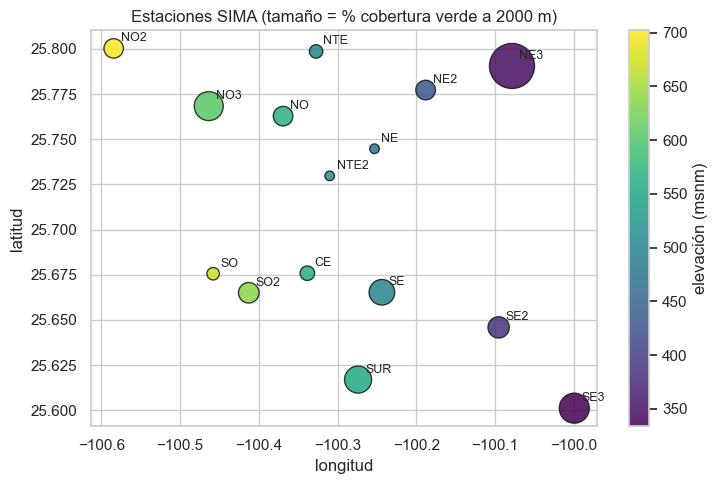

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sc = ax.scatter(fijos.lon, fijos.lat, s=40 + 14 * fijos[f"verde_{RADIO}"], c=fijos.elev, cmap="viridis", edgecolor="k", alpha=.85)
for e, r in fijos.iterrows(): ax.annotate(e, (r.lon, r.lat), xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.colorbar(sc, label="elevación (msnm)")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title(f"Estaciones SIMA (tamaño = % cobertura verde a {RADIO} m)")
plt.tight_layout(); plt.show()

# Variable respuesta binaria
Para cada contaminante: `y = 1` si el promedio mensual de la estación-mes supera el percentil `PERCENTIL` de ese contaminante (por defecto la mediana). **A diferencia de v2, el umbral se calcula solo con los meses de entrenamiento** (anteriores a `FECHA_CORTE`), para que la prueba no influya en cómo se define "alto". El mismo umbral se aplica después al periodo de prueba.

Como hay estacionalidad e incluso una baja general en 2025, la proporción de meses "altos" **no será igual** en entrenamiento y prueba; es parte de lo que se evalúa.

In [4]:
base = base.sort_values(["estacion", "fecha_mes"]).reset_index(drop=True)
base["RAINF_log"] = np.log1p(base["RAINF"])
base["humeda"] = (base["temporada"] == "húmeda").astype(int)
base["anio2025"] = (base["fecha_mes"].str[:4] == "2025").astype(int)
base["t"] = (base["fecha_mes"].str[:4].astype(int) - 2024) * 12 + base["fecha_mes"].str[5:7].astype(int) - 1   # 0..23

T_CORTE = (int(FECHA_CORTE[:4]) - 2024) * 12 + int(FECHA_CORTE[5:7]) - 1     # primer t de prueba
print(f"Entrenamiento: t < {T_CORTE} (hasta {base.loc[base.t == T_CORTE - 1, 'fecha_mes'].iloc[0]}) | "
      f"Prueba: t >= {T_CORTE} (desde {FECHA_CORTE})")

umbrales = {c: base.loc[base.t < T_CORTE, c].quantile(PERCENTIL / 100) for c in CONTAMINANTES}

filas = []
for c in CONTAMINANTES:
    for nombre, m in [("entrenamiento", base.t < T_CORTE), ("prueba", base.t >= T_CORTE)]:
        v = base.loc[m, c].dropna()
        filas.append({"contaminante": c, "periodo": nombre, "umbral": umbrales[c], "n_validos": len(v),
                      "n_alto (y=1)": int((v > umbrales[c]).sum()), "% alto": 100 * (v > umbrales[c]).mean()})
pd.DataFrame(filas).set_index(["contaminante", "periodo"])

Entrenamiento: t < 18 (hasta 2025-06) | Prueba: t >= 18 (desde 2025-07)


umbral  n_validos  n_alto (y=1)  % alto
contaminante periodo                                               
PM10         entrenamiento  58.999        264           132  50.000
             prueba         58.999         89            11  12.360
PM2.5        entrenamiento  20.089        165            82  49.697
             prueba         20.089         55            11  20.000
NO2          entrenamiento  14.082        244           122  50.000
             prueba         14.082         82            34  41.463
O3           entrenamiento  27.893        259           129  49.807
             prueba         27.893         84            49  58.333

# Preparación de los datos
Tres especificaciones (todas con meteorología, O3, temporada húmeda, año 2025 y estado del mes anterior `y_rez`):

| Spec. | Vegetación | Ubicación | Idea |
|---|---|---|---|
| **A** | NDVI + cobertura verde | — | Modelo v2: trata a todas las estaciones con la misma línea base |
| **B** *(principal)* | NDVI + cobertura verde | `lat`, `elev` | Cada estación tiene una línea base distinta según *dónde* está; el efecto de la vegetación se lee **a igualdad de ubicación** |
| **C** | solo NDVI (mensual) | absorbida | Una intercepción propia por estación (efecto fijo). Absorbe todo lo que no cambia en el tiempo (`verde`, `lat`, `elev`), por eso **no puede estimar el efecto de la cobertura verde**; sirve para ver si el NDVI *mensual* tiene efecto dentro de cada estación. Se ajusta con penalización L2 porque sin ella separa casi perfectamente |

- Estandarización (z-score) con **media y desviación del entrenamiento**, aplicada igual al periodo de prueba. Los odds ratio de las continuas se leen *por cada 1 DE*; los de las binarias, de 0 a 1.
- `y_rez` solo existe si el mes anterior de la misma estación existe y es consecutivo. En el primer mes de prueba, `y_rez` es el último mes de entrenamiento (observado): es un pronóstico a un mes, sin información del futuro.
- Casos completos (se eliminan filas con faltantes en y o en algún predictor). La lluvia se usa como `log(1 + lluvia)`.

In [5]:
def preparar(c, spec=None, corte=None, anio=None, rezago=None, ubic=None):
    # Devuelve un dict con y/X/datos de entrenamiento y prueba. Los argumentos permiten comparar especificaciones.
    spec = SPEC_PRINCIPAL if spec is None else spec
    corte = T_CORTE if corte is None else corte
    anio = INCLUIR_ANIO if anio is None else anio
    rezago = INCLUIR_Y_REZAGADA if rezago is None else rezago
    ubic = (spec == "B") if ubic is None else ubic

    d = base.copy()
    umbral = d.loc[d.t < corte, c].quantile(PERCENTIL / 100)                 # umbral solo con el entrenamiento
    d["y"] = (d[c] > umbral).astype(float).where(d[c].notna())
    consecutivo = d.groupby("estacion")["t"].diff() == 1
    d["y_rez"] = d.groupby("estacion")["y"].shift(1).where(consecutivo)

    cont = [f"ndvi_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"]
    if spec in ("A", "B"): cont = [f"verde_{RADIO}"] + cont
    if ubic: cont = cont + VARS_UBICACION
    extra = ["humeda"] + (["anio2025"] if anio else []) + (["y_rez"] if rezago else [])

    d = d.dropna(subset=["y"] + cont + extra).copy()
    trn, tst = d[d.t < corte], d[d.t >= corte]
    mu, sd = trn[cont].mean(), trn[cont].std()

    estaciones = sorted(trn.estacion.unique())
    def matriz(z):
        X = ((z[cont] - mu) / sd).copy()
        for e in extra: X[e] = z[e]
        if spec == "C":
            for s in estaciones[1:]: X["est_" + s] = (z.estacion == s).astype(float)   # la 1.ª estación es la referencia
        return sm.add_constant(X, has_constant="add")

    Xtr, Xte = matriz(trn), matriz(tst)
    constantes = [k for k in Xtr.columns if k != "const" and Xtr[k].std() == 0]       # p. ej. anio2025 si el corte es 2025-01
    Xtr, Xte = Xtr.drop(columns=constantes), Xte.drop(columns=constantes)
    return dict(ytr=trn["y"].astype(int), Xtr=Xtr, dtr=trn, yte=tst["y"].astype(int), Xte=Xte, dte=tst,
                umbral=umbral, cont=cont, spec=spec)

datos = {c: preparar(c) for c in CONTAMINANTES}
pd.DataFrame({c: {"n entrenamiento": len(datos[c]["ytr"]), "n prueba": len(datos[c]["yte"]),
                  "% y=1 entren.": 100 * datos[c]["ytr"].mean(), "% y=1 prueba": 100 * datos[c]["yte"].mean(),
                  "n estaciones": datos[c]["dtr"]["estacion"].nunique(),
                  "estaciones en prueba": datos[c]["dte"]["estacion"].nunique()} for c in CONTAMINANTES}).T

,n entrenamiento,n prueba,% y=1 entren.,% y=1 prueba,n estaciones,estaciones en prueba
PM10,205.000,66.000,48.293,9.091,15.000,12.000
PM2.5,105.000,30.000,55.238,13.333,11.000,8.000
NO2,187.000,58.000,49.198,43.103,15.000,12.000
O3,199.000,58.000,54.774,53.448,15.000,12.000


# Multicolinealidad (VIF)
VIF > 5 (o > 10) indica predictores muy correlacionados entre sí. Se calcula sobre el entrenamiento del modelo principal.

Antes de elegir las variables de ubicación se revisó la correlación entre los atributos fijos de las estaciones: **`lon` y `elev` tienen r = −0.97** (hacia el oeste, la ciudad sube), así que meter ambas sería meter la misma información dos veces. Se usa `elev` (que además tiene una lectura física: ventilación y capa de mezcla) y `lat` (eje norte-sur).

In [6]:
print("Correlación entre atributos fijos de las 15 estaciones:")
display(fijos[["lat", "lon", "elev", f"verde_{RADIO}", f"ndvi_{RADIO}_medio"]].corr())

vif = {}
for c in CONTAMINANTES:
    X = datos[c]["Xtr"]
    vif[c] = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print("\nVIF (modelo principal, entrenamiento):")
pd.DataFrame(vif).drop(index="const")

Correlación entre atributos fijos de las 15 estaciones:


,lat,lon,elev,verde_2000,ndvi_2000_medio
lat,1.000,-0.355,0.144,0.046,-0.297
lon,-0.355,1.000,-0.971,0.464,0.599
elev,0.144,-0.971,1.000,-0.478,-0.557
verde_2000,0.046,0.464,-0.478,1.000,0.854
ndvi_2000_medio,-0.297,0.599,-0.557,0.854,1.000



VIF (modelo principal, entrenamiento):


,PM10,PM2.5,NO2,O3
verde_2000,3.833,8.074,3.888,3.812
ndvi_2000,3.312,6.145,3.239,3.393
TOUT,4.424,3.675,4.831,5.341
RH,2.345,2.025,2.216,2.330
RAINF_log,1.646,1.452,1.622,1.594
WSR,2.071,2.431,1.975,1.978
lat,1.446,3.032,1.472,1.467
elev,2.090,2.447,2.132,2.190
humeda,4.715,3.739,4.356,4.444
anio2025,1.563,1.833,1.521,1.458


# Especificación y resultados del modelo
Modelo logit: $\log\frac{p}{1-p} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$, con $p = P(y=1)$, ajustado **solo con el periodo de entrenamiento**.
- Máxima verosimilitud (`statsmodels.Logit`) con errores estándar **agrupados por estación**.
- Odds ratio $OR = e^{\beta}$ (por 1 DE en las continuas). $OR>1$ sube la probabilidad de nivel alto; $OR<1$ la baja.
- Con `y_rez` el modelo es **autologístico**: los coeficientes se leen *dado el estado del mes anterior* (efecto de corto plazo).
- En el modelo B, el OR de `verde` se lee **a igualdad de latitud y elevación**: compara estaciones parecidas en ubicación pero con distinta vegetación a su alrededor. Es un efecto *entre estaciones* (la cobertura verde no cambia con el tiempo), y con solo 15 estaciones es una comparación frágil. El OR del NDVI, en cambio, mezcla diferencias entre estaciones y variación mensual dentro de cada una.

In [7]:
def ajustar_sm(y, X, grupos):
    return sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos}, maxiter=200)

def tabla_or(m):
    ic = np.exp(m.conf_int())
    return pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "IC95_inf": ic[0], "IC95_sup": ic[1], "p": m.pvalues})

modelos, tablas = {}, {}
for c in CONTAMINANTES:
    D = datos[c]
    m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
    modelos[c], tablas[c] = m, tabla_or(m)
    print(f"\n{c} (spec {SPEC_PRINCIPAL}) n={int(m.nobs)} | pseudo-R² McFadden={m.prsquared:.3f} | AIC={m.aic:.1f}")
    display(tablas[c])


PM10 (spec B) n=205 | pseudo-R² McFadden=0.373 | AIC=202.1


,coef,OR,IC95_inf,IC95_sup,p
const,-0.822,0.440,0.146,1.325,0.144
verde_2000,-0.571,0.565,0.327,0.978,0.041
ndvi_2000,0.175,1.192,0.637,2.228,0.583
TOUT,-1.186,0.305,0.144,0.649,0.002
RH,-1.318,0.268,0.129,0.556,0.000
RAINF_log,-0.423,0.655,0.408,1.051,0.079
WSR,-0.126,0.882,0.490,1.587,0.674
lat,0.035,1.036,0.655,1.639,0.880
elev,-0.485,0.616,0.337,1.126,0.115
humeda,0.746,2.109,0.460,9.676,0.337



PM2.5 (spec B) n=105 | pseudo-R² McFadden=0.413 | AIC=108.8


,coef,OR,IC95_inf,IC95_sup,p
const,0.594,1.811,1.078,3.043,0.025
verde_2000,-0.417,0.659,0.342,1.269,0.212
ndvi_2000,-1.156,0.315,0.126,0.784,0.013
TOUT,0.491,1.633,0.490,5.447,0.425
RH,0.811,2.250,1.055,4.797,0.036
RAINF_log,-0.470,0.625,0.458,0.853,0.003
WSR,-0.370,0.691,0.346,1.379,0.294
lat,-0.619,0.538,0.253,1.143,0.107
elev,-0.194,0.824,0.337,2.013,0.670
humeda,-2.928,0.053,0.010,0.298,0.001



NO2 (spec B) n=187 | pseudo-R² McFadden=0.581 | AIC=132.5


,coef,OR,IC95_inf,IC95_sup,p
const,-3.175,0.042,0.009,0.196,0.000
verde_2000,-0.691,0.501,0.178,1.413,0.191
ndvi_2000,0.857,2.355,1.048,5.295,0.038
TOUT,-1.111,0.329,0.098,1.106,0.072
RH,-0.950,0.387,0.145,1.032,0.058
RAINF_log,0.276,1.318,0.720,2.413,0.370
WSR,-1.287,0.276,0.105,0.726,0.009
lat,0.481,1.617,0.766,3.414,0.208
elev,0.750,2.117,0.674,6.649,0.199
humeda,1.787,5.970,0.610,58.455,0.125



O3 (spec B) n=199 | pseudo-R² McFadden=0.492 | AIC=163.1


,coef,OR,IC95_inf,IC95_sup,p
const,-2.200,0.111,0.035,0.354,0.000
verde_2000,0.048,1.049,0.344,3.203,0.933
ndvi_2000,0.113,1.120,0.474,2.645,0.797
TOUT,-0.930,0.395,0.151,1.034,0.059
RH,-2.977,0.051,0.013,0.203,0.000
RAINF_log,0.662,1.938,0.684,5.491,0.213
WSR,-0.039,0.962,0.533,1.734,0.897
lat,-0.660,0.517,0.253,1.056,0.070
elev,0.012,1.012,0.455,2.248,0.977
humeda,2.487,12.025,1.063,136.054,0.045


In [8]:
# ¿Cambia el efecto de la vegetación al incluir la ubicación? Comparación A (sin ubicación) vs B (con ubicación) vs C (efecto fijo, penalizado)
def ajustar_ridge(y, X):
    return LogisticRegression(C=RIDGE_C, max_iter=5000).fit(X.drop(columns="const"), y)

filas = []
for c in CONTAMINANTES:
    for spec in ["A", "B"]:
        D = preparar(c, spec=spec)
        m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
        filas.append({"contaminante": c, "spec": spec, "n": int(m.nobs),
                      f"OR verde_{RADIO}": np.exp(m.params[f"verde_{RADIO}"]), f"p verde_{RADIO}": m.pvalues[f"verde_{RADIO}"],
                      f"OR ndvi_{RADIO}": np.exp(m.params[f"ndvi_{RADIO}"]), f"p ndvi_{RADIO}": m.pvalues[f"ndvi_{RADIO}"]})
    D = preparar(c, spec="C"); r = ajustar_ridge(D["ytr"], D["Xtr"])
    coef = pd.Series(r.coef_[0], index=D["Xtr"].columns.drop("const"))
    filas.append({"contaminante": c, "spec": "C (ridge)", "n": len(D["ytr"]),
                  f"OR ndvi_{RADIO}": np.exp(coef[f"ndvi_{RADIO}"])})
comp_veg = pd.DataFrame(filas).set_index(["contaminante", "spec"])
display(comp_veg)
print("C no tiene OR de verde (absorbida por el efecto fijo) ni p-valores (la penalización los invalida); el OR de C es solo orientativo.")

n  OR verde_2000  p verde_2000  OR ndvi_2000  \
contaminante spec                                                        
PM10         A          205          0.696         0.163         1.217   
             B          205          0.565         0.041         1.192   
             C (ridge)  205            NaN           NaN         0.929   
PM2.5        A          105          1.103         0.686         0.341   
             B          105          0.659         0.212         0.315   
             C (ridge)  105            NaN           NaN         0.546   
NO2          A          187          0.540         0.054         1.546   
             B          187          0.501         0.191         2.355   
             C (ridge)  187            NaN           NaN         0.810   
O3           A          199          0.787         0.514         1.645   
             B          199          1.049         0.933         1.120   
             C (ridge)  199            NaN           NaN         0.892   

                        p ndvi_2000  
contaminante spec                    
PM10         A                0.601  
             B                0.583  
             C (ridge)          NaN  
PM2.5        A                0.019  
             B                0.013  
             C (ridge)          NaN  
NO2          A                0.257  
             B                0.038  
             C (ridge)          NaN  
O3           A                0.077  
             B                0.797  
             C (ridge)          NaN

C no tiene OR de verde (absorbida por el efecto fijo) ni p-valores (la penalización los invalida); el OR de C es solo orientativo.


### ¿Depende el resultado de una sola estación? (leave-one-station-out)
`verde` solo toma 15 valores distintos y la estación **NE3** tiene mucha más cobertura verde que el resto, así que puede dominar el coeficiente. Se vuelve a ajustar el modelo principal quitando una estación a la vez.

In [9]:
v = f"verde_{RADIO}"
filas = []
for c in CONTAMINANTES:
    D = datos[c]
    for e in sorted(D["dtr"].estacion.unique()):
        k = D["dtr"].estacion != e
        try:
            m = ajustar_sm(D["ytr"][k], D["Xtr"][k], D["dtr"].loc[k, "estacion"])
            filas.append({"contaminante": c, "sin estación": e, "OR verde": np.exp(m.params[v]), "p verde": m.pvalues[v]})
        except Exception:
            filas.append({"contaminante": c, "sin estación": e, "OR verde": np.nan, "p verde": np.nan})
loo = pd.DataFrame(filas)
resumen = loo.groupby("contaminante").agg(OR_min=("OR verde", "min"), OR_max=("OR verde", "max"),
                                          n_signif=("p verde", lambda s: int((s < .05).sum())), n_ajustes=("p verde", "size"))
resumen["OR completo"] = [np.exp(modelos[c].params[v]) for c in resumen.index]
display(resumen[["OR completo", "OR_min", "OR_max", "n_signif", "n_ajustes"]])
print("Estación cuya salida más cambia el OR de verde:")
display(loo.assign(dist=lambda t: (np.log(t["OR verde"]) - t["contaminante"].map(lambda c: modelos[c].params[v])).abs())
        .sort_values("dist", ascending=False).groupby("contaminante").head(2).drop(columns="dist").set_index(["contaminante", "sin estación"]))

,OR completo,OR_min,OR_max,n_signif,n_ajustes
contaminante,,,,,
NO2,0.501,0.271,0.929,2,15
O3,1.049,0.348,1.624,0,15
PM10,0.565,0.471,1.202,8,15
PM2.5,0.659,0.540,2.429,1,11


Estación cuya salida más cambia el OR de verde:


OR verde  p verde
contaminante sin estación                   
PM2.5        SE3              2.429    0.477
O3           NE3              0.348    0.265
PM2.5        SE2              1.422    0.679
PM10         NE3              1.202    0.693
NO2          NE2              0.929    0.915
             NE3              0.271    0.312
O3           NTE2             0.578    0.414
PM10         SE               0.701    0.147

# Validación de supuestos
Todos los diagnósticos usan el **periodo de entrenamiento** (con el que se ajustó el modelo).

### Linealidad del logit
Cada predictor continuo **que cambia en el tiempo** se divide en 5 grupos (cuantiles) y se grafica el logit de la proporción de `y=1` contra el promedio del predictor; deberían seguir aproximadamente una recta. (`verde`, `lat` y `elev` toman solo 15 valores —uno por estación—, por lo que este gráfico no aplica.)

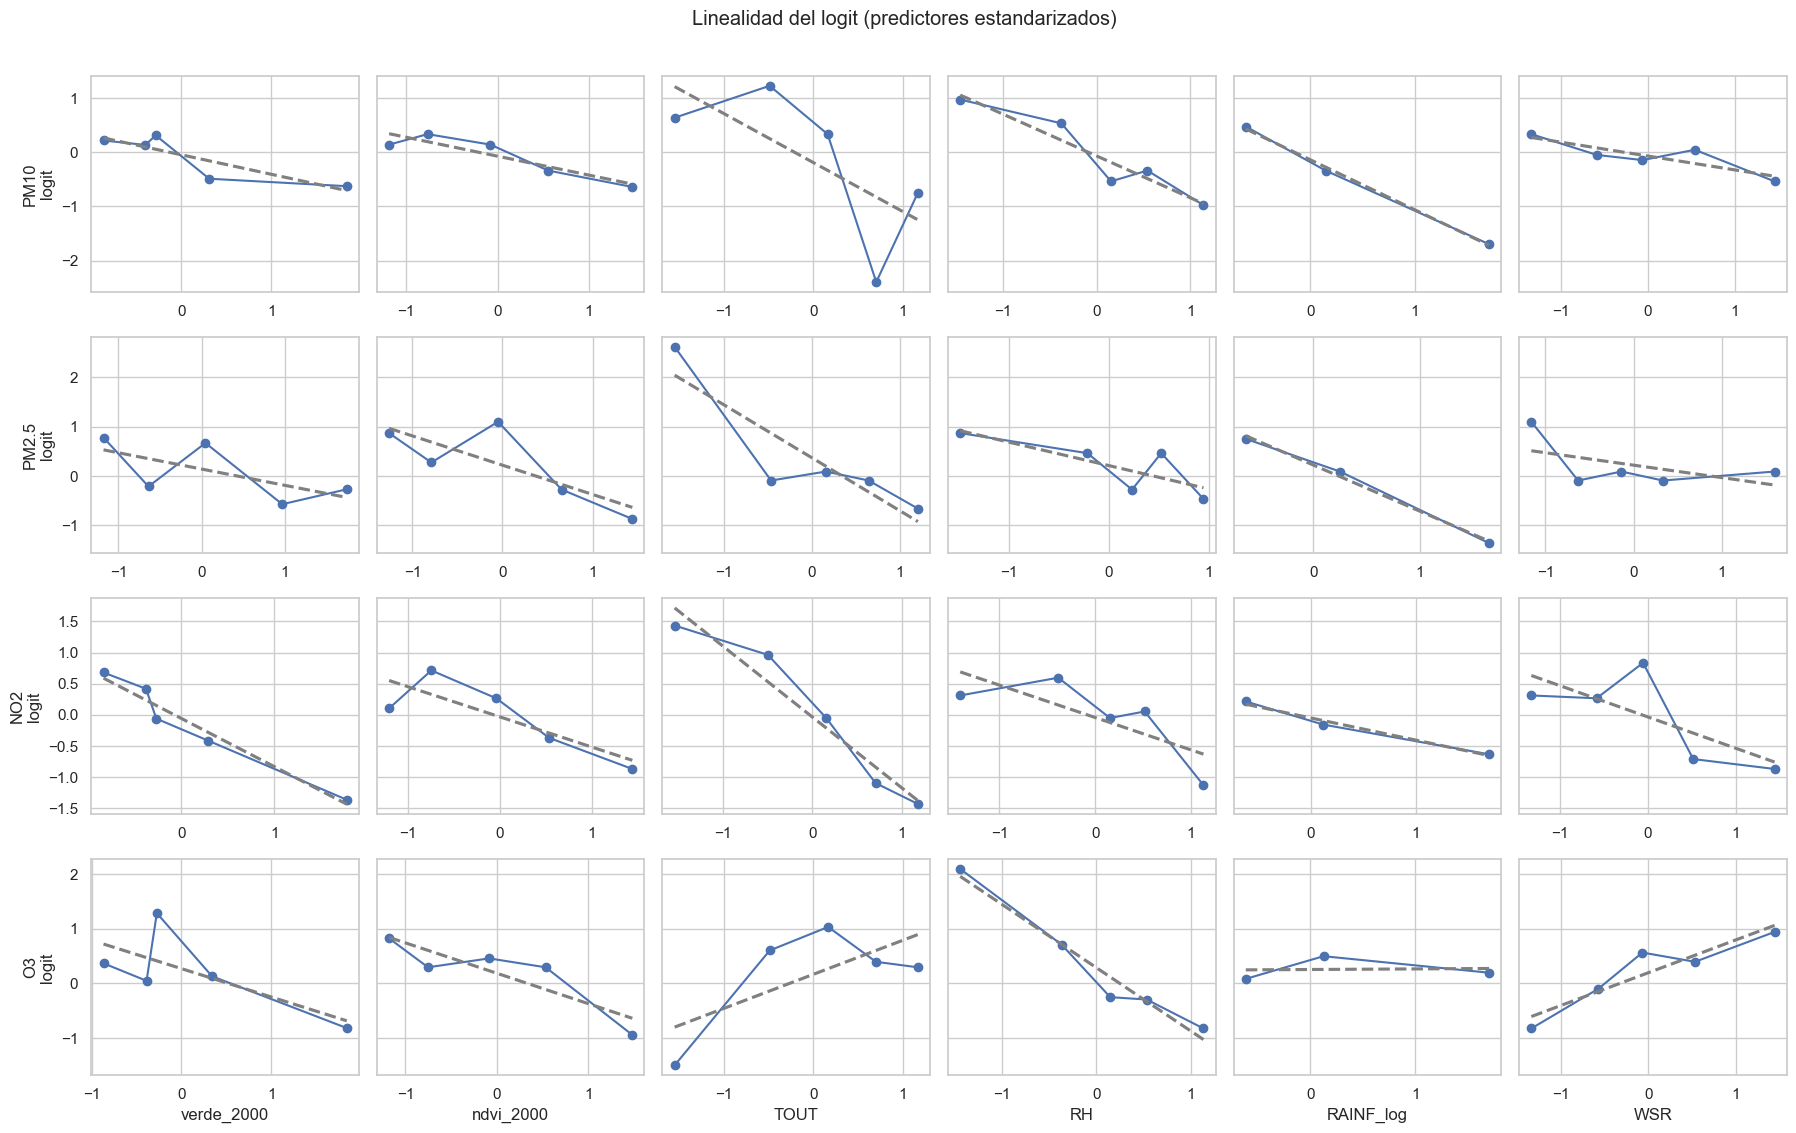

In [10]:
def logit_emp(y, x, bins=5):
    g = pd.DataFrame({"x": x, "y": y})
    g["b"] = pd.qcut(g["x"], bins, duplicates="drop")
    t = g.groupby("b", observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    t["logit"] = np.log((t.s + 0.5) / (t.n - t.s + 0.5))
    return t

VARS_TIEMPO = [f"verde_{RADIO}", f"ndvi_{RADIO}", "TOUT", "RH", "RAINF_log", "WSR"]
fig, axes = plt.subplots(len(CONTAMINANTES), len(VARS_TIEMPO), figsize=(3 * len(VARS_TIEMPO), 2.8 * len(CONTAMINANTES)), sharey="row")
for i, c in enumerate(CONTAMINANTES):
    D = datos[c]
    for j, vv in enumerate(VARS_TIEMPO):
        t = logit_emp(D["ytr"], D["Xtr"][vv]); ax = axes[i, j]
        ax.plot(t.x, t.logit, "o-")
        sns.regplot(x=t.x, y=t.logit, scatter=False, ci=None, color="gray", line_kws={"ls": "--"}, ax=ax)
        ax.set_xlabel(vv if i == len(CONTAMINANTES) - 1 else ""); ax.set_ylabel(f"{c}\nlogit" if j == 0 else "")
plt.suptitle("Linealidad del logit (predictores estandarizados)", y=1.01); plt.tight_layout(); plt.show()

### Observaciones influyentes
Distancia de Cook; referencia usual: $4/n$.

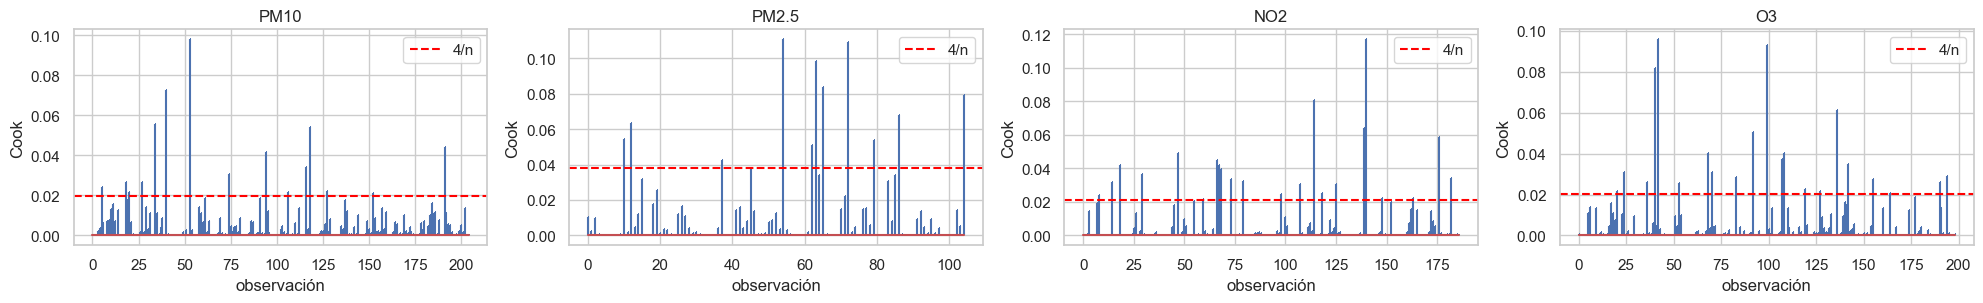

Top 5 influyentes PM10


,estacion,fecha_mes,PM10,cook
86,NE3,2025-03,75.764,0.098
73,NE3,2024-02,54.359,0.073
60,NE2,2025-01,53.751,0.055
220,SE,2024-05,74.340,0.054
337,SUR,2024-02,52.429,0.044


Top 5 influyentes PM2.5


,estacion,fecha_mes,PM2.5,cook
249,SE2,2024-10,21.440,0.111
276,SE3,2025-01,18.071,0.109
265,SE3,2024-02,18.135,0.098
268,SE3,2024-05,31.281,0.084
351,SUR,2025-04,19.405,0.079


Top 5 influyentes NO2


,estacion,fecha_mes,NO2,cook
276,SE3,2025-01,13.278,0.117
232,SE,2025-05,14.371,0.080
275,SE3,2024-12,14.234,0.064
338,SUR,2024-03,13.555,0.059
83,NE3,2024-12,15.022,0.049


Top 5 influyentes O3


,estacion,fecha_mes,O3,cook
76,NE3,2024-05,27.361,0.096
197,NTE2,2024-06,24.477,0.093
74,NE3,2024-03,29.076,0.082
253,SE2,2025-02,28.236,0.061
158,NO3,2025-03,22.592,0.050


In [11]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.2))
influyentes = {}
for ax, c in zip(axes, CONTAMINANTES):
    D = datos[c]
    glm = sm.GLM(D["ytr"], D["Xtr"], family=sm.families.Binomial()).fit()
    cook = pd.Series(glm.get_influence().cooks_distance[0], index=D["dtr"].index)
    ax.stem(range(len(cook)), cook.values, markerfmt=","); ax.axhline(4 / len(cook), color="red", ls="--", label="4/n")
    ax.set_title(c); ax.set_xlabel("observación"); ax.set_ylabel("Cook"); ax.legend()
    influyentes[c] = D["dtr"].loc[cook.nlargest(5).index, ["estacion", "fecha_mes", c]].assign(cook=cook.nlargest(5))
plt.tight_layout(); plt.show()
for c in CONTAMINANTES:
    print(f"Top 5 influyentes {c}"); display(influyentes[c])

### Bondad de ajuste (entrenamiento)
Razón de verosimilitud (completo vs. solo constante), Hosmer-Lemeshow ($H_0$: ajusta bien; p alto = bien) y McFadden R².

In [12]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({"y": y.values, "p": p.values}); t["grupo"] = pd.qcut(t["p"], g, duplicates="drop")
    r = t.groupby("grupo", observed=True).agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    chi2 = (((r.obs - r.esp) ** 2) / (r.esp * (1 - r.esp / r.n))).sum(); gl = len(r) - 2
    return chi2, gl, 1 - stats.chi2.cdf(chi2, gl)

gof = []
for c in CONTAMINANTES:
    D = datos[c]; m_ml = sm.Logit(D["ytr"], D["Xtr"]).fit(disp=0, maxiter=200)
    hl, gl, p_hl = hosmer_lemeshow(D["ytr"], m_ml.predict(D["Xtr"]))
    gof.append({"contaminante": c, "McFadden R2": m_ml.prsquared, "LR chi2": m_ml.llr, "p (LR)": m_ml.llr_pvalue,
                "HL chi2": hl, "HL gl": gl, "p (HL)": p_hl})
pd.DataFrame(gof).set_index("contaminante")

,McFadden R2,LR chi2,p (LR),HL chi2,HL gl,p (HL)
contaminante,,,,,,
PM10,0.373,105.889,0.000,12.274,8,0.139
PM2.5,0.413,59.600,0.000,7.196,8,0.516
NO2,0.581,150.668,0.000,10.357,8,0.241
O3,0.492,134.938,0.000,6.095,8,0.637


### Independencia: residuos por estación
Si el residuo medio de una estación se aleja de 0, el modelo está sesgado para esa estación (la ubicación o la vegetación no capturan su particularidad).

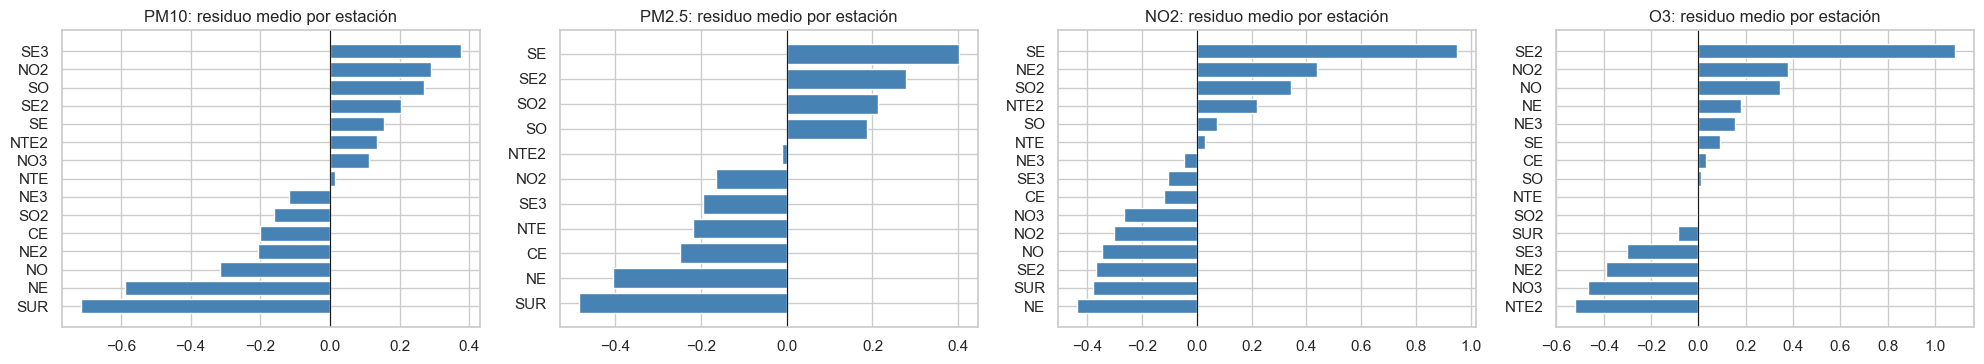

In [13]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5 * len(CONTAMINANTES), 3.8))
for ax, c in zip(axes, CONTAMINANTES):
    D = datos[c]; p = modelos[c].predict(D["Xtr"])
    res = ((D["ytr"] - p) / np.sqrt(p * (1 - p))).groupby(D["dtr"]["estacion"]).mean().sort_values()
    ax.barh(res.index, res.values, color="steelblue"); ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{c}: residuo medio por estación")
plt.tight_layout(); plt.show()

### Autocorrelación temporal de los residuos
Se compara la autocorrelación de los residuos de Pearson (rezago 1, meses consecutivos de la misma estación) entre especificaciones sucesivas; si el modelo captura la dependencia temporal debe acercarse a 0. Las especificaciones 1–4 son las de v2 (ahora ajustadas solo con el entrenamiento); la **5** agrega la ubicación y es el modelo principal de v3.

In [14]:
def ac_resid(d, r):
    t = d[["estacion", "t"]].assign(r=np.asarray(r)); t["r_prev"] = t.groupby("estacion")["r"].shift(1)
    x = t[t.groupby("estacion")["t"].diff() == 1][["r", "r_prev"]].dropna()
    rho, p = stats.pearsonr(x["r"], x["r_prev"]); return rho, p, len(x)

specs = {"1. Original":       dict(spec="A", anio=False, rezago=False),
         "2. Original tambien":                    dict(spec="A",  anio=False, rezago=False),
         "3. + año 2025":              dict(spec="A", anio=True,  rezago=False),
         "4. + y(t-1) [v2]":           dict(spec="A",  anio=True,  rezago=True),
         "5. + ubicación [principal v3]": dict(spec="B", anio=True, rezago=True)}
filas = []
for c in CONTAMINANTES:
    for nombre, kw in specs.items():
        D = preparar(c, **kw); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
        p = m.predict(D["Xtr"]); r = (D["ytr"] - p) / np.sqrt(p * (1 - p)); rho, pv, n = ac_resid(D["dtr"], r)
        filas.append({"contaminante": c, "especificación": nombre, "n": int(m.nobs), "AC residuos (rezago 1)": rho, "p (AC)": pv,
                      "McFadden R2": m.prsquared, f"OR verde_{RADIO}": np.exp(m.params[f"verde_{RADIO}"]),
                      f"p verde_{RADIO}": m.pvalues[f"verde_{RADIO}"]})
comp_ac = pd.DataFrame(filas).set_index(["contaminante", "especificación"]); display(comp_ac)

n  AC residuos (rezago 1)  \
contaminante especificación                                               
PM10         1. Original                    218                   0.281   
             2. Original tambien            218                   0.281   
             3. + año 2025                  218                   0.326   
             4. + y(t-1) [v2]               205                   0.051   
             5. + ubicación [principal v3]  205                   0.044   
PM2.5        1. Original                    128                   0.213   
             2. Original tambien            128                   0.213   
             3. + año 2025                  128                   0.090   
             4. + y(t-1) [v2]               105                  -0.056   
             5. + ubicación [principal v3]  105                  -0.074   
NO2          1. Original                    202                   0.591   
             2. Original tambien            202                   0.591   
             3. + año 2025                  202                   0.589   
             4. + y(t-1) [v2]               187                  -0.023   
             5. + ubicación [principal v3]  187                  -0.028   
O3           1. Original                    215                   0.463   
             2. Original tambien            215                   0.463   
             3. + año 2025                  215                   0.465   
             4. + y(t-1) [v2]               199                   0.057   
             5. + ubicación [principal v3]  199                   0.052   

                                            p (AC)  McFadden R2  \
contaminante especificación                                       
PM10         1. Original                     0.000        0.262   
             2. Original tambien             0.000        0.262   
             3. + año 2025                   0.000        0.326   
             4. + y(t-1) [v2]                0.493        0.362   
             5. + ubicación [principal v3]   0.556        0.373   
PM2.5        1. Original                     0.036        0.287   
             2. Original tambien             0.036        0.287   
             3. + año 2025                   0.382        0.337   
             4. + y(t-1) [v2]                0.614        0.400   
             5. + ubicación [principal v3]   0.508        0.413   
NO2          1. Original                     0.000        0.317   
             2. Original tambien             0.000        0.317   
             3. + año 2025                   0.000        0.324   
             4. + y(t-1) [v2]                0.776        0.555   
             5. + ubicación [principal v3]   0.723        0.581   
O3           1. Original                     0.000        0.281   
             2. Original tambien             0.000        0.281   
             3. + año 2025                   0.000        0.281   
             4. + y(t-1) [v2]                0.453        0.470   
             5. + ubicación [principal v3]   0.499        0.492   

                                            OR verde_2000  p verde_2000  
contaminante especificación                                              
PM10         1. Original                            0.527         0.022  
             2. Original tambien                    0.527         0.022  
             3. + año 2025                          0.697         0.267  
             4. + y(t-1) [v2]                       0.696         0.163  
             5. + ubicación [principal v3]          0.565         0.041  
PM2.5        1. Original                            1.772         0.048  
             2. Original tambien                    1.772         0.048  
             3. + año 2025                          1.060         0.830  
             4. + y(t-1) [v2]                       1.103         0.686  
             5. + ubicación [principal v3]          0.659         0.212  
NO2          1. Original        

### Autocorrelación espacial (I de Moran por estación)
Ahora que hay coordenadas se puede revisar si **estaciones cercanas se parecen**, algo que v2 no pudo evaluar. Se calcula la I de Moran con pesos $w_{ij}=1/d_{ij}$ (distancia en km entre estaciones) sobre tres cantidades por estación: el **nivel medio del contaminante** (¿hay estructura espacial en los datos?) y el **residuo medio** de los modelos A y B (¿la sigue habiendo después de incluir la ubicación?). Valor esperado bajo independencia: $-1/(n-1)$. El p-valor es de permutación (9 999 reordenamientos de las estaciones).

Con 11–15 estaciones la prueba tiene poca potencia: un p alto no demuestra ausencia de dependencia espacial.

In [15]:
def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180; a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

def moran(valores, nperm=9999, seed=0):
    v = valores.dropna(); est = v.index
    lat, lon = UBIC.loc[est, "lat"].values, UBIC.loc[est, "lon"].values
    Dm = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
    W = np.divide(1, Dm, out=np.zeros_like(Dm), where=Dm > 0)
    def I(x): z = x - x.mean(); return (len(x) / W.sum()) * (z @ W @ z) / (z @ z)
    obs = I(v.values); rng = np.random.default_rng(seed)
    perm = np.array([I(rng.permutation(v.values)) for _ in range(nperm)])
    return obs, -1 / (len(v) - 1), (np.sum(np.abs(perm - perm.mean()) >= abs(obs - perm.mean())) + 1) / (nperm + 1), len(v)

def resid_estacion(c, spec):
    D = preparar(c, spec=spec); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"]); p = m.predict(D["Xtr"])
    return ((D["ytr"] - p) / np.sqrt(p * (1 - p))).groupby(D["dtr"]["estacion"]).mean()

filas = []
for c in CONTAMINANTES:
    series = {"nivel medio del contaminante": base.groupby("estacion")[c].mean(),
              "residuo modelo A (sin ubicación)": resid_estacion(c, "A"),
              "residuo modelo B (con ubicación)": resid_estacion(c, "B")}
    for nombre, s in series.items():
        I, EI, p, n = moran(s); filas.append({"contaminante": c, "variable": nombre, "n estaciones": n, "I de Moran": I, "E[I]": EI, "p (permutación)": p})
pd.DataFrame(filas).set_index(["contaminante", "variable"])

n estaciones  I de Moran  \
contaminante variable                                                     
PM10         nivel medio del contaminante                15      -0.080   
             residuo modelo A (sin ubicación)            15      -0.089   
             residuo modelo B (con ubicación)            15      -0.075   
PM2.5        nivel medio del contaminante                11      -0.079   
             residuo modelo A (sin ubicación)            11      -0.111   
             residuo modelo B (con ubicación)            11      -0.170   
NO2          nivel medio del contaminante                15      -0.019   
             residuo modelo A (sin ubicación)            15      -0.120   
             residuo modelo B (con ubicación)            15      -0.145   
O3           nivel medio del contaminante                15      -0.033   
             residuo modelo A (sin ubicación)            15      -0.096   
             residuo modelo B (con ubicación)            15      -0.110   

                                                E[I]  p (permutación)  
contaminante variable                                                  
PM10         nivel medio del contaminante     -0.071            0.878  
             residuo modelo A (sin ubicación) -0.071            0.736  
             residuo modelo B (con ubicación) -0.071            0.961  
PM2.5        nivel medio del contaminante     -0.100            0.787  
             residuo modelo A (sin ubicación) -0.100            0.890  
             residuo modelo B (con ubicación) -0.100            0.357  
NO2          nivel medio del contaminante     -0.071            0.266  
             residuo modelo A (sin ubicación) -0.071            0.326  
             residuo modelo B (con ubicación) -0.071            0.123  
O3           nivel medio del contaminante     -0.071            0.444  
             residuo modelo A (sin ubicación) -0.071            0.587  
             residuo modelo B (con ubicación) -0.071            0.415

# Eficiencia del modelo y análisis de errores — validación temporal
**Todas las estaciones aparecen en entrenamiento y en prueba;** lo que se separa es el tiempo. Se hacen dos pruebas:

1. **Corte único:** se ajusta con los meses anteriores a `FECHA_CORTE` y se predicen los posteriores (por defecto, entrena 2024-01 a 2025-06 y prueba 2025-07 a 2025-12). Es lo más cercano a una situación real, pero son pocos puntos y el semestre de prueba puede tener una mezcla de clases muy distinta (ver sección 2).
2. **Walk-forward (hacia adelante):** se entrena con los primeros 12 meses y se predice el mes 13; luego se entrena con 13 y se predice el 14, y así hasta el mes 24 (umbral y z-score recalculados en cada paso solo con el pasado). Junta más predicciones y es más estable.

Se comparan las especificaciones **A, B y C** contra dos referencias simples: **persistencia** (predecir que el mes será igual al anterior) y **mayoría del entrenamiento**. Un modelo solo aporta si supera a la persistencia, porque `y_rez` ya viene incluida. Umbral de clasificación: 0.5. El AUC no se calcula si el periodo de prueba tiene una sola clase.

In [16]:
def metricas(y, p, pred=None):
    pred = (np.asarray(p) >= 0.5).astype(int) if pred is None else np.asarray(pred).astype(int)
    y = np.asarray(y)
    auc = roc_auc_score(y, p) if (p is not None and len(np.unique(y)) > 1) else np.nan
    return {"n": len(y), "exactitud": accuracy_score(y, pred), "AUC": auc,
            "precisión": precision_score(y, pred, zero_division=0), "sensibilidad": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0)}

def predecir(c, spec, corte):
    # Ajusta con t < corte y devuelve (datos de prueba, probabilidades) para t >= corte
    D = preparar(c, spec=spec, corte=corte)
    if spec == "C": modelo = ajustar_ridge(D["ytr"], D["Xtr"]); p = modelo.predict_proba(D["Xte"].drop(columns="const"))[:, 1]
    else:           modelo = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"]); p = np.asarray(modelo.predict(D["Xte"]))
    return D, p

NOMBRES = {"A": "A. sin ubicación (v2)", "B": "B. con ubicación", "C": "C. efecto fijo (ridge)"}
filas, cv_pred = [], {}
for c in CONTAMINANTES:
    for spec in "ABC":
        D, p = predecir(c, spec, T_CORTE)
        filas.append({"contaminante": c, "modelo": NOMBRES[spec], **metricas(D["yte"], p)})
        cv_pred[(c, spec)] = pd.DataFrame({"y": D["yte"].values, "proba": p, "pred": (p >= .5).astype(int),
                                           "estacion": D["dte"]["estacion"].values, "fecha_mes": D["dte"]["fecha_mes"].values})
    D = preparar(c, spec="B")
    filas.append({"contaminante": c, "modelo": "referencia: persistencia", **metricas(D["yte"], None, D["dte"]["y_rez"].values)})
    filas.append({"contaminante": c, "modelo": "referencia: mayoría entren.", **metricas(D["yte"], None, np.full(len(D["yte"]), int(D["ytr"].mean() >= .5)))})
res_corte = pd.DataFrame(filas).set_index(["contaminante", "modelo"])
print(f"Corte único: entrena hasta antes de {FECHA_CORTE}, prueba desde {FECHA_CORTE}")
res_corte

Corte único: entrena hasta antes de 2025-07, prueba desde 2025-07


n  exactitud   AUC  precisión  \
contaminante modelo                                                        
PM10         A. sin ubicación (v2)        66      0.924 0.906      0.667   
             B. con ubicación             66      0.924 0.931      0.667   
             C. efecto fijo (ridge)       66      0.909 0.936      0.500   
             referencia: persistencia     66      0.924   NaN      0.667   
             referencia: mayoría entren.  66      0.909   NaN      0.000   
PM2.5        A. sin ubicación (v2)        30      0.367 0.548      0.105   
             B. con ubicación             30      0.367 0.538      0.105   
             C. efecto fijo (ridge)       30      0.400 0.596      0.111   
             referencia: persistencia     30      0.867   NaN      0.500   
             referencia: mayoría entren.  30      0.133   NaN      0.133   
NO2          A. sin ubicación (v2)        58      0.845 0.909      1.000   
             B. con ubicación             58      0.845 0.903      0.944   
             C. efecto fijo (ridge)       58      0.879 0.967      1.000   
             referencia: persistencia     58      0.845   NaN      1.000   
             referencia: mayoría entren.  58      0.569   NaN      0.000   
O3           A. sin ubicación (v2)        58      0.724 0.818      0.727   
             B. con ubicación             58      0.707 0.830      0.750   
             C. efecto fijo (ridge)       58      0.776 0.879      0.821   
             referencia: persistencia     58      0.776   NaN      0.737   
             referencia: mayoría entren.  58      0.534   NaN      0.534   

                                          sensibilidad    F1  
contaminante modelo                                           
PM10         A. sin ubicación (v2)               0.333 0.444  
             B. con ubicación                    0.333 0.444  
             C. efecto fijo (ridge)              0.333 0.400  
             referencia: persistencia            0.333 0.444  
             referencia: mayoría entren.         0.000 0.000  
PM2.5        A. sin ubicación (v2)               0.500 0.174  
             B. con ubicación                    0.500 0.174  
             C. efecto fijo (ridge)              0.500 0.182  
             referencia: persistencia            0.500 0.500  
             referencia: mayoría entren.         1.000 0.235  
NO2          A. sin ubicación (v2)               0.640 0.780  
             B. con ubicación                    0.680 0.791  
             C. efecto fijo (ridge)              0.720 0.837  
             referencia: persistencia            0.640 0.780  
             referencia: mayoría entren.         0.000 0.000  
O3           A. sin ubicación (v2)               0.774 0.750  
             B. con ubicación                    0.677 0.712  
             C. efecto fijo (ridge)              0.742 0.780  
             referencia: persistencia            0.903 0.812  
             referencia: mayoría entren.         1.000 0.697

In [17]:
filas, wf_pred = [], {}
for c in CONTAMINANTES:
    acum = {s: [] for s in "ABC"}; pers = []
    for k in range(INICIO_WALK_FORWARD, 24):
        for spec in "ABC":
            D, p = predecir(c, spec, k)
            sel = (D["dte"]["t"] == k).values                       # solo el mes k (un paso adelante)
            acum[spec].append(pd.DataFrame({"y": D["yte"].values[sel], "proba": p[sel], "t": k, "estacion": D["dte"]["estacion"].values[sel],
                                            "y_rez": D["dte"]["y_rez"].values[sel] if "y_rez" in D["dte"] else np.nan}))
    for spec in "ABC":
        r = pd.concat(acum[spec]); wf_pred[(c, spec)] = r
        filas.append({"contaminante": c, "modelo": NOMBRES[spec], **metricas(r.y, r.proba.values)})
    r = wf_pred[(c, "B")]
    filas.append({"contaminante": c, "modelo": "referencia: persistencia", **metricas(r.y, None, r.y_rez.fillna(0).values)})
    filas.append({"contaminante": c, "modelo": "referencia: mayoría", **metricas(r.y, None, np.full(len(r), int(r.y.mean() >= .5)))})
res_wf = pd.DataFrame(filas).set_index(["contaminante", "modelo"])
print(f"Walk-forward: {INICIO_WALK_FORWARD} meses iniciales, se predice un mes a la vez hasta el mes 24")
res_wf

Walk-forward: 12 meses iniciales, se predice un mes a la vez hasta el mes 24


n  exactitud   AUC  precisión  \
contaminante modelo                                                      
PM10         A. sin ubicación (v2)     135      0.763 0.785      0.585   
             B. con ubicación          135      0.778 0.795      0.615   
             C. efecto fijo (ridge)    135      0.778 0.854      0.605   
             referencia: persistencia  135      0.785   NaN      0.625   
             referencia: mayoría       135      0.711   NaN      0.000   
PM2.5        A. sin ubicación (v2)      65      0.677 0.764      0.667   
             B. con ubicación           65      0.677 0.722      0.667   
             C. efecto fijo (ridge)     65      0.646 0.735      0.652   
             referencia: persistencia   65      0.769   NaN      0.789   
             referencia: mayoría        65      0.569   NaN      0.569   
NO2          A. sin ubicación (v2)     113      0.779 0.875      0.895   
             B. con ubicación          113      0.805 0.884      0.884   
             C. efecto fijo (ridge)    113      0.858 0.927      0.898   
             referencia: persistencia  113      0.832   NaN      0.860   
             referencia: mayoría       113      0.513   NaN      0.000   
O3           A. sin ubicación (v2)     123      0.724 0.820      0.761   
             B. con ubicación          123      0.699 0.801      0.724   
             C. efecto fijo (ridge)    123      0.797 0.879      0.811   
             referencia: persistencia  123      0.780   NaN      0.814   
             referencia: mayoría       123      0.577   NaN      0.577   

                                       sensibilidad    F1  
contaminante modelo                                        
PM10         A. sin ubicación (v2)            0.615 0.600  
             B. con ubicación                 0.615 0.615  
             C. efecto fijo (ridge)           0.667 0.634  
             referencia: persistencia         0.641 0.633  
             referencia: mayoría              0.000 0.000  
PM2.5        A. sin ubicación (v2)            0.865 0.753  
             B. con ubicación                 0.865 0.753  
             C. efecto fijo (ridge)           0.811 0.723  
             referencia: persistencia         0.811 0.800  
             referencia: mayoría              1.000 0.725  
NO2          A. sin ubicación (v2)            0.618 0.731  
             B. con ubicación                 0.691 0.776  
             C. efecto fijo (ridge)           0.800 0.846  
             referencia: persistencia         0.782 0.819  
             referencia: mayoría              0.000 0.000  
O3           A. sin ubicación (v2)            0.761 0.761  
             B. con ubicación                 0.775 0.748  
             C. efecto fijo (ridge)           0.845 0.828  
             referencia: persistencia         0.803 0.809  
             referencia: mayoría              1.000 0.732

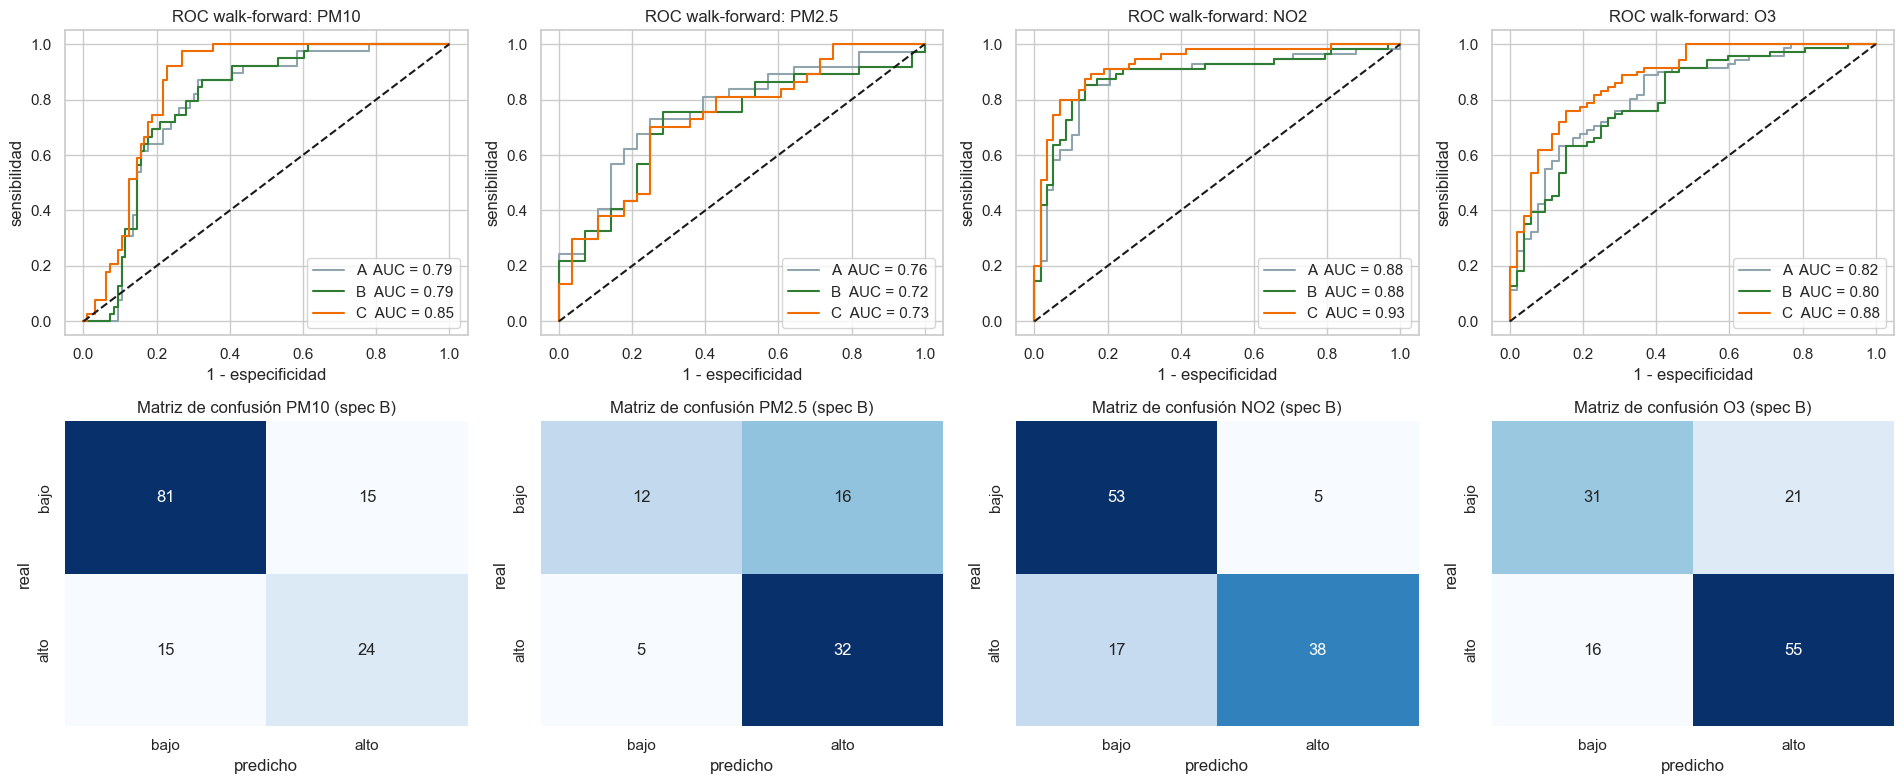

In [18]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.8 * len(CONTAMINANTES), 8))
for j, c in enumerate(CONTAMINANTES):
    for spec, col in zip("ABC", ["#90A4AE", "#2E7D32", "#EF6C00"]):
        r = wf_pred[(c, spec)]; fpr, tpr, _ = roc_curve(r.y, r.proba)
        axes[0, j].plot(fpr, tpr, color=col, label=f"{spec}  AUC = {roc_auc_score(r.y, r.proba):.2f}")
    axes[0, j].plot([0, 1], [0, 1], "k--"); axes[0, j].set_title(f"ROC walk-forward: {c}")
    axes[0, j].set_xlabel("1 - especificidad"); axes[0, j].set_ylabel("sensibilidad"); axes[0, j].legend(loc="lower right")
    r = wf_pred[(c, SPEC_PRINCIPAL)]
    sns.heatmap(confusion_matrix(r.y, (r.proba >= .5).astype(int)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, j],
                xticklabels=["bajo", "alto"], yticklabels=["bajo", "alto"])
    axes[1, j].set_title(f"Matriz de confusión {c} (spec {SPEC_PRINCIPAL})"); axes[1, j].set_xlabel("predicho"); axes[1, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### Análisis de errores
Dónde se equivoca el modelo principal en las predicciones **walk-forward**: por estación y por mes. Aquí sí tiene sentido mirar estación por estación, porque todas están en la prueba.

PM10


,tasa_error,errores,n,zona,verde_2000
estacion,,,,,
NO3,0.429,3,7,Noroeste 3,28.202
NTE2,0.333,4,12,Norte 2,0.560
SE,0.333,4,12,Sureste,21.386
NE2,0.333,4,12,Noreste 2,11.377
SE3,0.250,3,12,Sureste,30.509
NO,0.182,2,11,Noroeste,11.266


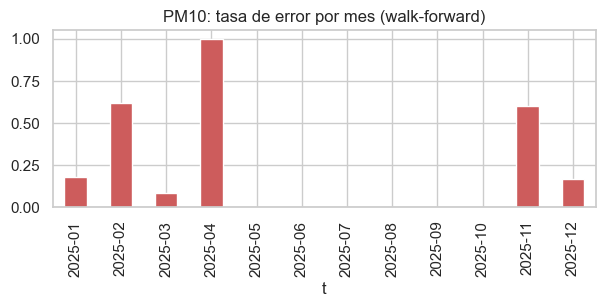

PM2.5


,tasa_error,errores,n,zona,verde_2000
estacion,,,,,
SUR,0.600,3,5,Sur,24.203
SE3,0.429,3,7,Sureste,30.509
NO2,0.400,2,5,Noroeste 2,11.125
CE,0.333,3,9,Centro,4.946
NTE2,0.333,4,12,Norte 2,0.560
SE,0.300,3,10,Sureste,21.386


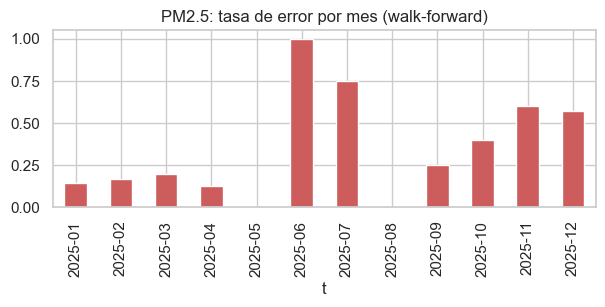

NO2


,tasa_error,errores,n,zona,verde_2000
estacion,,,,,
SE,0.333,4,12,Sureste,21.386
NO2,0.286,2,7,Noroeste 2,11.125
NO3,0.250,1,4,Noroeste 3,28.202
SUR,0.250,2,8,Sur,24.203
NE3,0.222,2,9,Noreste 3,72.278
SO2,0.167,2,12,Suroeste 2,12.753


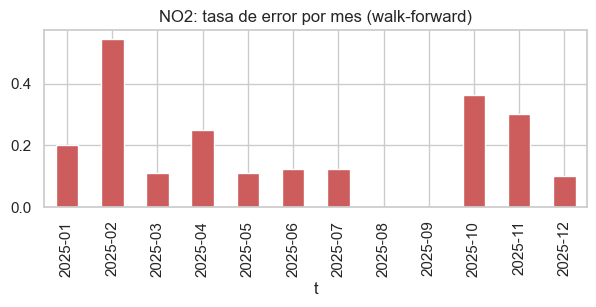

O3


,tasa_error,errores,n,zona,verde_2000
estacion,,,,,
NO3,0.571,4,7,Noroeste 3,28.202
SE2,0.571,4,7,Sureste 2,14.006
NO2,0.400,4,10,Noroeste 2,11.125
SE3,0.333,4,12,Sureste,30.509
SE,0.333,4,12,Sureste,21.386
SO,0.333,1,3,Suroeste,2.886


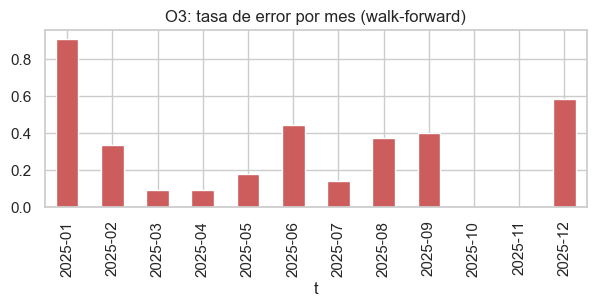

In [19]:
for c in CONTAMINANTES:
    r = wf_pred[(c, SPEC_PRINCIPAL)].assign(error=lambda t: ((t.proba >= .5).astype(int) != t.y).astype(int))
    por_est = r.groupby("estacion").error.agg(["mean", "sum", "size"]).rename(columns={"mean": "tasa_error", "sum": "errores", "size": "n"})
    por_est = por_est.join(UBIC[["zona"]]).join(fijos[[f"verde_{RADIO}"]])
    print(c); display(por_est.sort_values("tasa_error", ascending=False).head(6))
    por_mes = r.groupby("t").error.mean().rename(index=lambda k: base.loc[base.t == k, "fecha_mes"].iloc[0])
    por_mes.plot.bar(figsize=(7, 2.3), title=f"{c}: tasa de error por mes (walk-forward)", color="indianred"); plt.show()

# Variables más importantes
Odds ratio por 1 DE (IC 95 %, errores agrupados por estación) del **modelo principal**, ajustado con el entrenamiento. Línea en 1 = sin efecto; si el intervalo cruza el 1, el efecto no es significativo.

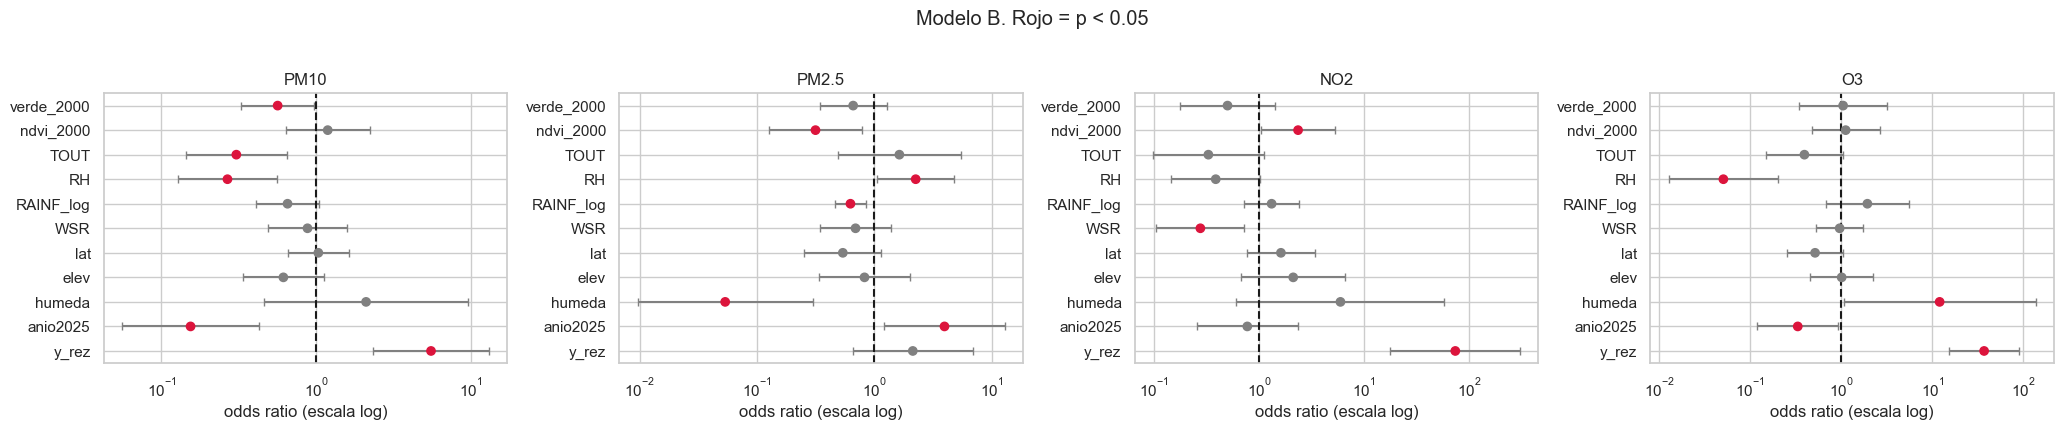

,PM10,PM2.5,NO2,O3
|coef| estandarizado,,,,
anio2025,1.868,1.375,0.257,1.098
y_rez,1.714,0.754,4.307,3.611
RH,1.318,0.811,0.950,2.977
TOUT,1.186,0.491,1.111,0.930
humeda,0.746,2.928,1.787,2.487
verde_2000,0.571,0.417,0.691,0.048
elev,0.485,0.194,0.750,0.012
RAINF_log,0.423,0.470,0.276,0.662
ndvi_2000,0.175,1.156,0.857,0.113


In [20]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(5.2 * len(CONTAMINANTES), 4.2), sharey=False)
for ax, c in zip(axes, CONTAMINANTES):
    t = tablas[c].drop(index="const").iloc[::-1]; sig = t.p < 0.05
    ax.errorbar(t.OR, range(len(t)), xerr=[t.OR - t.IC95_inf, t.IC95_sup - t.OR], fmt="none", ecolor="gray", capsize=3)
    ax.scatter(t.OR, range(len(t)), c=np.where(sig, "crimson", "gray"), zorder=3)
    ax.axvline(1, color="k", ls="--"); ax.set_xscale("log"); ax.set_title(c); ax.set_xlabel("odds ratio (escala log)")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
plt.suptitle(f"Modelo {SPEC_PRINCIPAL}. Rojo = p < 0.05", y=1.02); plt.tight_layout(); plt.show()

imp = pd.DataFrame({c: tablas[c]["coef"].abs() for c in CONTAMINANTES}).drop(index="const")
imp.sort_values(CONTAMINANTES[0], ascending=False).rename_axis("|coef| estandarizado")

# Lectura de los resultados (v3)

*Las cifras corresponden a la configuración por defecto (entrena 2024-01 a 2025-06, prueba 2025-07 a 2025-12, radio 1000 m, umbral = mediana del entrenamiento). Si cambias los parámetros, vuelve a leer las tablas.*

**1. Qué se hizo con la ubicación.** Las 15 estaciones del documento coinciden con las de la base. Se agregaron `lat`, `lon` y `elev`; en el modelo principal entran `lat` y `elev` porque `lon` y `elev` son casi la misma variable (r = −0.97). No se ajustó un modelo separado por estación: con ~18 meses de entrenamiento por estación (menos en PM2.5) no hay datos para eso. La alternativa fue (B) darle a cada estación una línea base según su ubicación y su vegetación, y (C) una intercepción propia por estación, usada como control de sensibilidad.

**2. La división es solo temporal.** Las 15 estaciones (11 en PM2.5, que no tiene datos en NE2, NE3, NO ni NO3) aparecen en entrenamiento y en prueba. El semestre de prueba es mucho más "limpio" que el resto: solo 12 % de los meses de PM10 y 20 % de PM2.5 quedan por encima del umbral (41 % en NO2). Por eso la exactitud en el corte único es poco informativa, y por eso se agregó el walk-forward.

**3. ¿Qué dice el modelo sobre la vegetación?** (que era el objetivo)
* **Cobertura verde (`verde_1000`, diferencia entre estaciones):** el OR es menor que 1 en los tres contaminantes (PM10 0.58, PM2.5 0.87, NO2 0.93), es decir, apunta a *menos* probabilidad de nivel alto, pero **ninguno es significativo** (p = 0.12, 0.69 y 0.91). En el análisis leave-one-station-out el resultado **no es estable**: quitar NE3 (la estación con 65 % de cobertura verde, mucho más que las demás) hace que el OR de PM10 pase a 4.95 (efecto contrario) y el de NO2 a 0.06 (p = 0.019). Es decir, con 15 estaciones y una sola muy distinta, el modelo no puede separar el efecto de la cobertura verde del de otras características de NE3. **No hay evidencia robusta de que la cobertura verde alrededor de la estación cambie la probabilidad de niveles altos.**
* **Lo que sí se movió respecto a v2:** el efecto de la cobertura verde sobre NO2 que aparecía en v2 (OR ≈ 0.33, p = 0.004, ajustado con todos los datos) no se sostiene aquí: ajustando solo con el entrenamiento baja a OR 0.64 (p = 0.08) y al incluir la ubicación a 0.93 (p = 0.91). La elevación absorbe parte de lo que antes se atribuía a la vegetación (elevación y cobertura verde tienen r = −0.41 entre estaciones).
* **NDVI mensual (dentro de cada estación, a lo largo del tiempo):** solo en **PM2.5** es significativo y va en el sentido de *protección*: por cada 1 DE más de NDVI, el OR de nivel alto es 0.34 (IC 95 % 0.16–0.74, p = 0.007). La especificación con efecto fijo por estación (C, penalizada) mantiene el mismo signo (OR 0.60), lo cual da algo de apoyo a que el efecto es temporal y no solo entre estaciones. En PM10 y NO2 el NDVI no es significativo y la dirección no es consistente entre especificaciones (OR 1.4 en B; 1.05 y 0.72 en C). Precaución con PM2.5: n = 104, 11 estaciones, la más verde (NE3) no tiene datos, y el NDVI sigue la estacionalidad (aunque se controla con `humeda`).

**4. Ubicación.** `lat` no es significativa en ningún caso. `elev` solo lo es en NO2 (OR 3.55 por 1 DE, p = 0.038: a mayor elevación, más probable un NO2 alto, a igualdad de lo demás). Con solo 15 estaciones y elevación correlacionada con NDVI medio (r = −0.64) y vegetación, se debe leer como pista, no como resultado firme. La I de Moran de los residuos no muestra autocorrelación espacial ni antes ni después de incluir la ubicación (todos los p > 0.2), pero con 11–15 puntos la prueba tiene poca potencia.

**5. Desempeño predictivo (walk-forward, 109–129 predicciones por contaminante).** Incluir la ubicación **casi no mejora la predicción**: AUC de B vs. A de 0.79 vs. 0.78 (PM10), 0.73 vs. 0.77 (PM2.5, algo peor) y 0.89 vs. 0.88 (NO2). La especificación C (efecto fijo) es la mejor en PM10 y NO2 (AUC 0.84 y 0.93). Contra la referencia de **persistencia** ("este mes será igual que el anterior") los modelos están empatados o por debajo en PM10 (exactitud 0.76–0.77 vs. 0.775) y PM2.5 (0.68–0.70 vs. 0.76); solo C en NO2 la supera (0.86 vs. 0.83). Gran parte de la capacidad predictiva viene de `y_rez` y de la meteorología (temperatura, humedad), no de la vegetación ni de la ubicación. En el corte único de PM2.5 el modelo clasifica mal (exactitud 0.43–0.46 con solo 4 meses altos de 28): los coeficientes de PM2.5 estimados con ~100 observaciones no se extrapolan bien al semestre más limpio.

**6. Supuestos.** La autocorrelación residual queda sin evidencia de dependencia con `y_rez` (rezago 1: 0.03, −0.08 y −0.03; p > 0.45). Hosmer-Lemeshow no rechaza el ajuste en PM10 ni PM2.5; en NO2 sí lo rechaza (p = 0.033), así que el ajuste de NO2 es mejorable. Los errores estándar agrupados con 11–15 estaciones siguen siendo aproximados. El `anio2025` de PM2.5 (OR 3.9) tiene signo contrario al de PM10 (OR 0.18) y solo se estima con enero–junio de 2025; no conviene interpretarlo.

**7. Recomendaciones.**
* Para afirmar algo sobre la **cobertura verde** hacen falta más estaciones o más contraste de vegetación (o una variable de vegetación que *cambie en el tiempo* y no sea el NDVI, que sigue las lluvias). Con los datos actuales, lo honesto es reportar "sin efecto detectable, resultado sensible a NE3".
* Si el equipo prefiere medir la vegetación *dentro* de cada estación, el camino es el NDVI mensual con efecto fijo por estación (spec. C); no se puede estimar la cobertura verde con esa especificación.
* Un umbral normativo (NOM) en lugar de la mediana evitaría que "alto" cambie de significado entre entrenamiento y prueba.